# 02 - Modeling: predicting churn

Setup: stratified 75/25 split (5,282 train, 1,761 test), seed 42.
Class imbalance (26.5 percent churners) is handled with class weights in
both models rather than resampling, so predicted probabilities stay
comparable and the training mix stays the real customer mix.

Models:
- Logistic regression (scaled features, class_weight="balanced")
- Random forest (class_weight="balanced_subsample", 400 trees)

Drivers are measured with SHAP on the logistic regression and cross-checked
with permutation importance on the test set.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn.evaluate import grouped_permutation_importance, metrics_at_threshold, threshold_sweep
from churn.features import load_data, make_xy
from churn.train import build_models, split_data

df = load_data("../data/raw/telco_churn.csv")
X, y = make_xy(df)
X_train, X_test, y_train, y_test = split_data(X, y)
print(f"Train: {len(X_train)}, test: {len(X_test)}, test churn rate: {y_test.mean():.1%}")

Train: 5282, test: 1761, test churn rate: 26.5%


In [2]:
models = build_models()
probs = {}
rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    probs[name] = pipe.predict_proba(X_test)[:, 1]
    m = metrics_at_threshold(y_test, probs[name], threshold=0.5)
    rows.append({"model": name, **{k: round(v, 3) for k, v in m.items() if k != "threshold"}})
results = pd.DataFrame(rows).set_index("model")
results

,roc_auc,accuracy,precision,recall,f1
model,,,,,
logistic_regression,0.846,0.750,0.519,0.797,0.628
random_forest,0.839,0.786,0.593,0.619,0.606


Logistic regression has the higher ROC AUC (0.846 versus 0.839) and much
higher recall at the 0.50 threshold (0.80 versus 0.62). The random forest
is more precise (0.59 versus 0.52) but misses more churners. For a
retention use case, recall is the metric that pays, so the logistic model
is the one saved by `src/churn/train.py`.

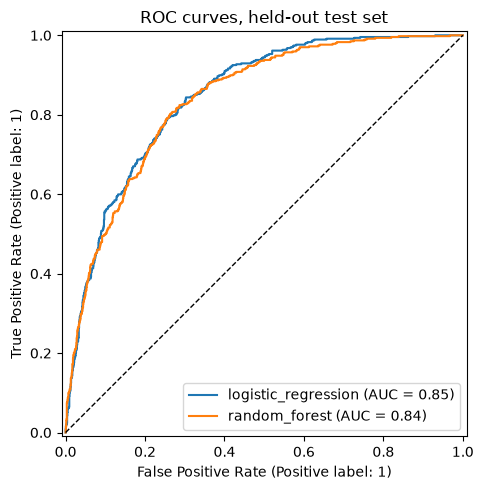

In [3]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6.5, 5))
for name, pipe in models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_title("ROC curves, held-out test set")
fig.tight_layout()
fig.savefig("../reports/figures/roc_curves.png", dpi=150)
plt.show()

## Threshold choice

The default 0.50 threshold is a poor fit for retention outreach. At 0.30
the logistic model catches 92.7 percent of churners, at the cost of
precision falling to 0.43. Which point is right depends on the cost of an
outreach contact versus the value of a saved customer.

In [4]:
sweep = threshold_sweep(y_test, probs["logistic_regression"])
sweep.round(3)

,threshold,roc_auc,accuracy,precision,recall,f1
0,0.3,0.846,0.659,0.433,0.927,0.591
1,0.4,0.846,0.708,0.472,0.865,0.611
2,0.5,0.846,0.750,0.519,0.797,0.628
3,0.6,0.846,0.770,0.551,0.717,0.623
4,0.7,0.846,0.792,0.610,0.600,0.605


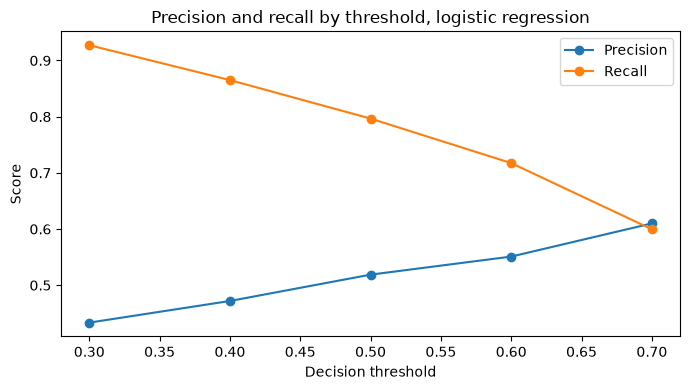

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["threshold"], sweep["precision"], marker="o", label="Precision")
ax.plot(sweep["threshold"], sweep["recall"], marker="o", label="Recall")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision and recall by threshold, logistic regression")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/threshold_tradeoff.png", dpi=150)
plt.show()

## Drivers: SHAP on the logistic regression

SHAP values are computed on the transformed (one-hot) feature space and
summed back to the original columns, so each bar is one input field.

In [6]:
import shap

pipe = models["logistic_regression"]
from scipy import sparse
_t = pipe[:-1].transform(X_test)
Xt_test = _t.toarray() if sparse.issparse(_t) else _t
_r = pipe[:-1].transform(X_train)
Xt_train = _r.toarray() if sparse.issparse(_r) else _r
feature_names = pipe[:-1].get_feature_names_out()

background = Xt_train[np.random.RandomState(0).choice(len(Xt_train), 200, replace=False)]
explainer = shap.Explainer(pipe[-1], background)
shap_values = explainer(Xt_test).values
mean_abs = np.abs(shap_values).mean(axis=0)

base_names = []
for name in feature_names:
    kind, rest = name.split("__", 1)
    if kind == "num":
        base_names.append(rest)
    else:
        base_names.append(rest.rsplit("_", 1)[0])
shap_by_base = (
    pd.DataFrame({"feature": base_names, "mean_abs_shap": mean_abs})
    .groupby("feature", as_index=False)["mean_abs_shap"].sum()
    .sort_values("mean_abs_shap", ascending=False)
)
shap_by_base.round(3)


/home/hatch/workspace/new-projects/telco-churn-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


,feature,mean_abs_shap
19,tenure,1.000
3,InternetService,0.713
0,Contract,0.610
4,MonthlyCharges,0.526
16,TotalCharges,0.401
13,StreamingMovies,0.335
14,StreamingTV,0.290
7,OnlineSecurity,0.243
10,PaymentMethod,0.225
15,TechSupport,0.216


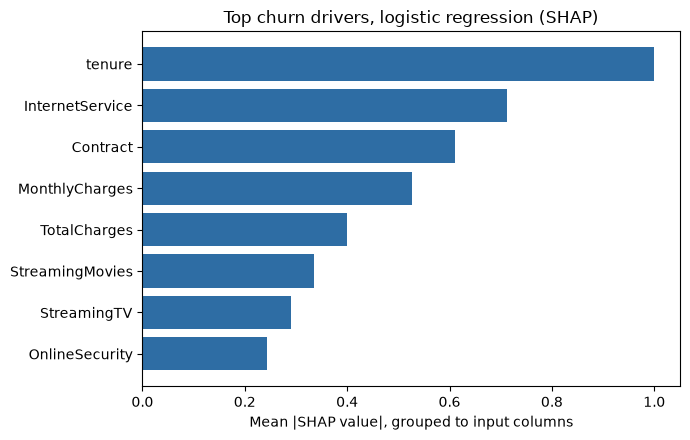

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
top = shap_by_base.head(8).iloc[::-1]
ax.barh(top["feature"], top["mean_abs_shap"], color="#2e6da4")
ax.set_xlabel("Mean |SHAP value|, grouped to input columns")
ax.set_title("Top churn drivers, logistic regression (SHAP)")
fig.tight_layout()
fig.savefig("../reports/figures/shap_drivers.png", dpi=150)
plt.show()

## Cross-check: permutation importance

Permutation importance on the test set (drop in ROC AUC when one column
is shuffled) tells the same story with a different method: tenure first,
then internet service and contract.

In [8]:
perm = grouped_permutation_importance(pipe, X_test, y_test)
perm.head(8).round(4)

,feature,importance_mean,importance_std
0,tenure,0.1616,0.0116
1,InternetService,0.0457,0.0051
2,Contract,0.0429,0.0054
3,MonthlyCharges,0.0330,0.0023
4,TotalCharges,0.0116,0.0036
5,StreamingMovies,0.0055,0.0017
6,StreamingTV,0.0047,0.0016
7,TechSupport,0.0046,0.0007


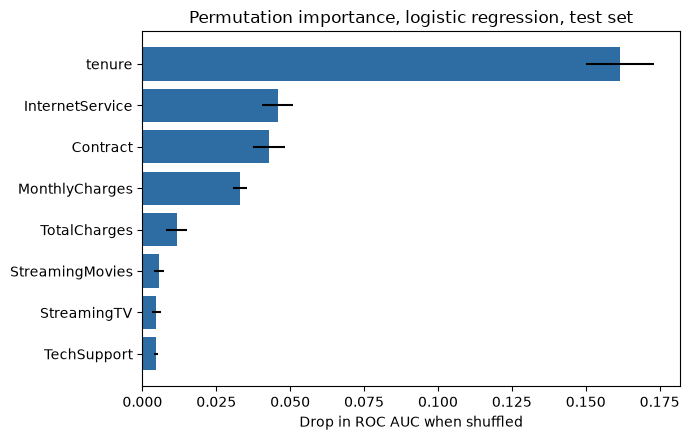

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
top = perm.head(8).iloc[::-1]
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#2e6da4")
ax.set_xlabel("Drop in ROC AUC when shuffled")
ax.set_title("Permutation importance, logistic regression, test set")
fig.tight_layout()
fig.savefig("../reports/figures/permutation_importance.png", dpi=150)
plt.show()

## Summary

- Logistic regression: AUC 0.846, accuracy 0.750, precision 0.519,
  recall 0.797 at threshold 0.50.
- Random forest: AUC 0.839, accuracy 0.786, precision 0.593,
  recall 0.619 at threshold 0.50.
- Top drivers by both SHAP and permutation importance: tenure, contract
  type, internet service, and monthly charges.
- Recommended operating point for retention outreach: threshold 0.30 to
  0.40, where recall is 0.87 to 0.93.